# XGBoost for IPL win probability

In [2]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError(
        "XGBoost is not installed in this Python environment. "
        "Install it in your project environment with: python -m pip install xgboost"
    ) from exc


## 1. Load the data

We use the same columns as the existing experiments. `match_id` is only for keeping deliveries from the same match together during validation; it is not a model input.

The newer seasons are kept aside until the final check, so we can see how the model does on matches that happened later.


In [3]:
DATA_CANDIDATES = [
    Path("data/processed/reduced/Final_data.csv"),
    Path("../data/processed/reduced/Final_data.csv"),
]
DATA_PATH = next((p.resolve() for p in DATA_CANDIDATES if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Can't find data/processed/reduced/Final_data.csv. "
        "Open the project folder in VS Code and check that the dataset is there."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} rows from {DATA_PATH}")
print(f"Matches: {df['match_id'].nunique():,}")
print(f"Seasons: {df['season_id'].min()}–{df['season_id'].max()}")

df.head()


Loaded 117,558 rows from C:\Users\Lenovo\Documents\IPL ML\data\processed\reduced\Final_data.csv
Matches: 1,063
Seasons: 2008–2026


,match_id,team_batting,team_bowling,current_score,season_id,match_date,city,venue,target_runs,runs_left,CRR,balls_left,RRR,wickets_left,runs_last_30,wickets_last_30,won
0,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,1,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,222,6.0,119,11.193277,10,1.0,0.0,0
1,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,2,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,221,6.0,118,11.237288,10,2.0,0.0,0
2,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,3,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,220,6.0,117,11.282051,10,3.0,0.0,0
3,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,4,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,219,6.0,116,11.327586,10,4.0,0.0,0
4,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,4,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,219,4.8,115,11.426087,10,4.0,0.0,0


In [4]:
FEATURES = [
    "target_runs",
    "runs_left",
    "CRR",
    "balls_left",
    "RRR",
    "wickets_left",
]
TARGET = "won"
GROUP = "match_id"

needed = FEATURES + [TARGET, GROUP, "season_id"]
assert df[needed].notna().all().all(), "Some required columns have missing values."
assert set(df[TARGET].unique()).issubset({0, 1}), "The target should contain 0 and 1 only."
assert not (df.groupby(GROUP)[TARGET].nunique() > 1).any(), "A match has more than one outcome label."

dev = df.loc[df["season_id"] <= 2024].copy().reset_index(drop=True)
test = df.loc[df["season_id"] >= 2025].copy().reset_index(drop=True)
assert not dev.empty and not test.empty, "Need development seasons through 2024 and a 2025+ holdout."
assert set(dev[GROUP]).isdisjoint(set(test[GROUP])), "A match appears in both development and holdout data."

X_dev = dev[FEATURES]
y_dev = dev[TARGET].astype(int)
groups_dev = dev[GROUP]
X_test = test[FEATURES]
y_test = test[TARGET].astype(int)

print(f"Development: {len(dev):,} rows across {groups_dev.nunique():,} matches (through 2024)")
print(f"Later-season holdout: {len(test):,} rows across {test[GROUP].nunique():,} matches (2025 onward)")
if "match_date" in test.columns:
    print("Latest date in holdout:", test["match_date"].max())


Development: 105,663 rows across 953 matches (through 2024)
Later-season holdout: 11,895 rows across 110 matches (2025 onward)
Latest date in holdout: 2026-05-01


## 2. Set up the models

The XGBoost settings below are just a starting point, not a tuned final model. `n_estimators` is the number of trees; `max_depth` limits how complicated each tree can get; `learning_rate` controls how much each new tree changes the model.

XGBoost doesn't need feature scaling. Logistic Regression does, so its scaler stays inside a pipeline.


In [5]:
def make_model(name):
    if name == "Logistic Regression":
        return Pipeline([
            ("scale", StandardScaler()),
            ("model", LogisticRegression(max_iter=2000)),
        ])

    if name == "XGBoost":
        return XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            n_estimators=300,
            learning_rate=0.05,
            max_depth=4,
            min_child_weight=10,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=5,
            tree_method="hist",
            n_jobs=-1,
            random_state=42,
        )

    raise ValueError(f"Unknown model: {name}")

MODEL_NAMES = ["Logistic Regression", "XGBoost"]


## 3. Compare them on grouped folds

Five-fold cross-validation gives us a few checks on the development seasons instead of trusting one split. Every fold keeps all rows from a match on one side, so deliveries from the same match can't leak into both training and validation.

We'll record log loss and Brier score (lower is better), plus ROC-AUC and accuracy (higher is better).


In [6]:
def score_model(y_true, probabilities):
    return {
        "log_loss": log_loss(y_true, probabilities, labels=[0, 1]),
        "brier": brier_score_loss(y_true, probabilities),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "accuracy": accuracy_score(y_true, probabilities >= 0.5),
    }

cv = GroupKFold(n_splits=5)
cv_rows = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_dev, y_dev, groups_dev), start=1
):
    train_matches = set(groups_dev.iloc[train_idx])
    val_matches = set(groups_dev.iloc[val_idx])
    assert train_matches.isdisjoint(val_matches), "A match leaked across a CV fold."

    X_train, X_val = X_dev.iloc[train_idx], X_dev.iloc[val_idx]
    y_train, y_val = y_dev.iloc[train_idx], y_dev.iloc[val_idx]

    for name in MODEL_NAMES:
        start = time.time()
        model = make_model(name)
        model.fit(X_train, y_train)
        p_val = model.predict_proba(X_val)[:, 1]

        row = {"model": name, "fold": fold, **score_model(y_val, p_val)}
        row["fit_seconds"] = time.time() - start
        cv_rows.append(row)
        print(f"Fold {fold}/5 | {name}: log loss = {row['log_loss']:.4f}")

cv_results = pd.DataFrame(cv_rows)
cv_summary = (
    cv_results.groupby("model")
    .agg(
        log_loss_mean=("log_loss", "mean"),
        log_loss_std=("log_loss", "std"),
        brier_mean=("brier", "mean"),
        roc_auc_mean=("roc_auc", "mean"),
        accuracy_mean=("accuracy", "mean"),
        total_fit_seconds=("fit_seconds", "sum"),
    )
    .sort_values("log_loss_mean")
)

display(cv_summary.round(4))


Fold 1/5 | Logistic Regression: log loss = 0.4273
Fold 1/5 | XGBoost: log loss = 0.4618
Fold 2/5 | Logistic Regression: log loss = 0.4609
Fold 2/5 | XGBoost: log loss = 0.4925
Fold 3/5 | Logistic Regression: log loss = 0.4736
Fold 3/5 | XGBoost: log loss = 0.5267
Fold 4/5 | Logistic Regression: log loss = 0.4206
Fold 4/5 | XGBoost: log loss = 0.4438
Fold 5/5 | Logistic Regression: log loss = 0.4201
Fold 5/5 | XGBoost: log loss = 0.4323


,log_loss_mean,log_loss_std,brier_mean,roc_auc_mean,accuracy_mean,total_fit_seconds
model,,,,,,
Logistic Regression,0.4405,0.0250,0.1454,0.8744,0.7839,0.4522
XGBoost,0.4714,0.0384,0.1533,0.8612,0.7686,3.8434


## 4. Check on later seasons

Now fit each model on all development seasons and check it on the newer seasons. We don't use these results to pick XGBoost settings; this is a final out-of-time check for this experiment.

The dataset only has part of the 2026 season, so remember that when reading the results.


In [7]:
holdout_rows = []
trained_models = {}

for name in MODEL_NAMES:
    model = make_model(name)
    model.fit(X_dev, y_dev)
    p_test = model.predict_proba(X_test)[:, 1]

    row = {"model": name, **score_model(y_test, p_test)}
    holdout_rows.append(row)
    trained_models[name] = model

holdout_results = (
    pd.DataFrame(holdout_rows)
    .set_index("model")
    .sort_values("log_loss")
)
display(holdout_results.round(4))


,log_loss,brier,roc_auc,accuracy
model,,,,
Logistic Regression,0.4244,0.1391,0.9001,0.7935
XGBoost,0.5771,0.1773,0.8572,0.7649


## 5. Which features did XGBoost use most?

This plot shows XGBoost's built-in feature-importance scores. Treat them as a rough look inside this particular model, not proof that a feature causes a win.


,feature,importance
0,RRR,0.5862
1,wickets_left,0.1116
2,target_runs,0.1046
3,runs_left,0.0891
4,CRR,0.0583
5,balls_left,0.0502


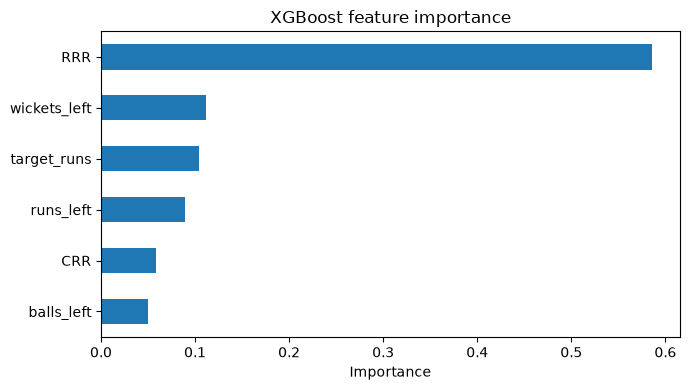

In [8]:
xgb_model = trained_models["XGBoost"]
feature_importance = (
    pd.DataFrame({
        "feature": FEATURES,
        "importance": xgb_model.feature_importances_,
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance.round(4))
feature_importance.sort_values("importance").plot(
    kind="barh", x="feature", y="importance", legend=False, figsize=(7, 4)
)
plt.title("XGBoost feature importance")
plt.xlabel("Importance")
plt.ylabel("")
plt.tight_layout()
plt.show()


## 6. Save the results

These CSVs keep the results from this run so we can bring them into the model comparison later. The dataset itself stays where it is.


In [9]:
# Find the project folder whether the notebook was opened from the root or models/.
ROOT_CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    (p.resolve() for p in ROOT_CANDIDATES if (p / ".git").exists()),
    Path.cwd().resolve(),
)
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

cv_results.to_csv(REPORT_DIR / "xgboost_grouped_cv_folds.csv", index=False)
cv_summary.to_csv(REPORT_DIR / "xgboost_grouped_cv_summary.csv")
holdout_results.to_csv(REPORT_DIR / "xgboost_temporal_holdout.csv")
feature_importance.to_csv(REPORT_DIR / "xgboost_feature_importance.csv", index=False)

print(f"Saved four reports to: {REPORT_DIR}")


Saved four reports to: C:\Users\Lenovo\Documents\IPL ML\reports


## What to look at

- In the cross-validation table, compare XGBoost with Logistic Regression across the same five folds.
- In the later-season table, pay attention to log loss and Brier score as well as ROC-AUC and accuracy.
- These settings haven't been tuned yet. If XGBoost doesn't beat the baseline, that's still a useful result. Don't keep changing settings based on the later-season holdout.
